# 第170章: 方針勾配と Actor-Critic — 行動を「出力」できるようにする

## Policy Gradient and Actor-Critic

---

### このノートブックの位置づけ

Unit 15（VLA）の**最初の章**です。ここまでのカリキュラムで、私たちは
「世界を内部に再現して**想像**する」ところ（Unit 11 世界モデル）まで到達しました。
しかし **行動を出力するモデル** は作っていません。Notebook 142・145 で扱った行動は
GridWorld の離散4方向だけで、連続的な行動を出す方針（policy）は一度も学習していません。

この章で、**方針そのものを勾配で学習する**という道具を手に入れます。
これが VLA（Vision-Language-Action）の "A" の土台になります。

### 学習目標

この章を終えると、以下ができるようになります：

- [ ] 価値ベース（Q学習）と方針ベースの違いを説明できる
- [ ] 方針勾配定理を導出し、REINFORCE を実装できる
- [ ] ベースラインが勾配の分散を下げる理由を説明し、**実測できる**
- [ ] Advantage Actor-Critic (A2C) を実装できる
- [ ] 連続行動をガウス方針でパラメータ化できる
- [ ] 行動空間の設計（関節空間 vs 作業空間、正規化）が学習しやすさを決めることを理解する
- [ ] Notebook 143 (DreamerV3) の actor-critic 部分を自力で読めるようになる

### 前提知識

| ノートブック | トピック |
|---|---|
| 142 | モデルベース強化学習の基礎（MDP, Q-Learning, Dyna-Q） |
| 145 | グリッドワールドの知能体（世界モデル + MPC） |
| 110-116 | 最適化手法（Adam, 勾配クリッピング） |
| 167 | ファインチューニングとアライメント（RLHF の図解で PPO に概念的に既出） |

**難易度**: ★★★★☆ | **所要時間**: 150-180分

## 目次

1. [環境セットアップ](#setup)
2. [なぜ方針を直接学ぶのか](#why)
3. [GridWorld の用意](#grid)
4. [REINFORCE — 方針勾配定理](#reinforce)
5. [ベースラインと Advantage — 分散を実測する](#baseline)
6. [ArmWorld — 連続行動・画像観測・言語指示の実験基盤](#armworld)
7. [ガウス方針による連続制御](#gaussian)
8. [よくある落とし穴: 方針と価値でトランクを共有する](#pitfall)
9. [既出知識との接続](#links)
10. [補足: gymnasium / MuJoCo への移行](#gym)
11. [まとめとチートシート](#summary)
12. [自己評価クイズ](#quiz)

---

<a id="setup"></a>
## 1. 環境セットアップ

In [1]:
# ============================================================
# 環境セットアップ
# ============================================================

import sys
import pathlib
import time

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# ArmWorld（Unit 15 共通の実験基盤）を import できるようにする。
# notebooks/vla/ から実行しても、リポジトリルートから実行しても通るようにしておく。
_here = pathlib.Path.cwd()
for _cand in (_here, _here / "notebooks" / "vla", _here.parent):
    if (_cand / "utils" / "armworld.py").exists():
        sys.path.insert(0, str(_cand))
        break
from utils import ArmWorld, ScriptedExpert, forward_kinematics, rollout  # noqa: E402
from utils.armworld import MAX_DELTA, MAX_EEF_STEP, SUCCESS_RADIUS       # noqa: E402

# 再現性（本リポジトリの規約）
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

plt.rcParams["figure.figsize"] = (12, 4.5)
plt.rcParams["font.size"] = 10
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

print("torch:", torch.__version__)
print("numpy:", np.__version__)
print("ArmWorld: MAX_DELTA =", MAX_DELTA, "/ MAX_EEF_STEP =", MAX_EEF_STEP,
      "/ SUCCESS_RADIUS =", SUCCESS_RADIUS)

torch: 2.9.1
numpy: 2.2.6
ArmWorld: MAX_DELTA = 0.2 / MAX_EEF_STEP = 0.12 / SUCCESS_RADIUS = 0.15


---

<a id="why"></a>
## 2. なぜ方針を直接学ぶのか

Notebook 142 では **Q学習**（価値ベース）を扱いました。行動を選ぶときは

$$a^* = \arg\max_a Q(s, a)$$

を計算します。GridWorld では行動が4つしかないので、4つ全部を試して一番大きいものを選べます。

### 連続行動では argmax が解けない

ロボットアームの関節に与える指令は**連続値**です。例えば2関節に $[-1, 1]$ の実数を送るなら、
行動空間は $[-1,1]^2$ という**非可算無限集合**です。ここで $\arg\max_a Q(s,a)$ は
もう「全部試す」では解けません。

素朴な対策は**離散化**ですが、次元の呪いに当たります。
$k$ 分割 × $d$ 次元 = $k^d$ 通り。アームの関節が増えるほど爆発します。

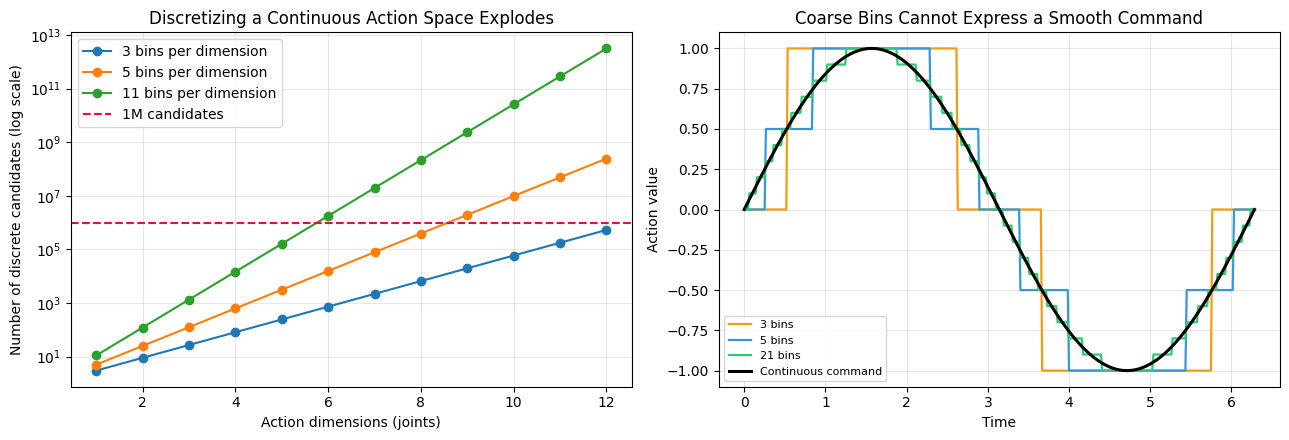

3 bins x 7 joints = 2187 candidates
11 bins x 7 joints = 19487171 candidates  <- argmax is no longer tractable


In [2]:
# ============================================================
# 図1: 行動の離散化は次元の呪いに当たる
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# --- 左: 離散化の候補数の爆発 ---
ax = axes[0]
dims = np.arange(1, 13)
for k in [3, 5, 11]:
    ax.semilogy(dims, k ** dims.astype(float), "o-", label=f"{k} bins per dimension")
ax.axhline(1e6, color="crimson", ls="--", lw=1.5, label="1M candidates")
ax.set_xlabel("Action dimensions (joints)")
ax.set_ylabel("Number of discrete candidates (log scale)")
ax.set_title("Discretizing a Continuous Action Space Explodes")
ax.legend()

# --- 右: 離散化すると細かい制御ができない ---
ax = axes[1]
t = np.linspace(0, 2 * np.pi, 400)
smooth = np.sin(t)
for k, color in [(3, "#F39C12"), (5, "#3498DB"), (21, "#2ECC71")]:
    bins = np.linspace(-1, 1, k)
    quantized = bins[np.abs(smooth[:, None] - bins[None, :]).argmin(axis=1)]
    ax.plot(t, quantized, color=color, lw=1.6, label=f"{k} bins")
ax.plot(t, smooth, "k-", lw=2.2, label="Continuous command")
ax.set_xlabel("Time")
ax.set_ylabel("Action value")
ax.set_title("Coarse Bins Cannot Express a Smooth Command")
ax.legend(loc="lower left", fontsize=8)

plt.tight_layout()
plt.show()

print("3 bins x 7 joints =", 3 ** 7, "candidates")
print("11 bins x 7 joints =", 11 ** 7, "candidates  <- argmax is no longer tractable")

### 方針ベースという答え

そこで、$Q$ を経由せず **方針そのものをパラメータ化**します。

$$\pi_\theta(a \mid s)$$

連続行動なら、例えばガウス分布のパラメータ（平均と標準偏差）をニューラルネットに出させます。
行動を決めるのは「分布からサンプルする」だけなので、**argmax を解く必要がありません**。

| | 価値ベース (Q学習) | 方針ベース (方針勾配) |
|---|---|---|
| 学習するもの | $Q(s,a)$ | $\pi_\theta(a\mid s)$ |
| 行動の決め方 | $\arg\max_a Q$ | 分布からサンプル |
| 連続行動 | argmax が解けない | **そのまま扱える** |
| 確率的方針 | 表現しにくい | 自然に表現できる |
| 多峰性（複数の正解） | 平均に潰れがち | 分布次第で表現可能 |
| 弱点 | — | **勾配の分散が大きい** |

最後の行がこの章の主題です。方針勾配は「そのまま使うと分散が大きすぎて学習が進まない」。
それをベースラインと Actor-Critic で抑える、という筋書きになります。

---

<a id="grid"></a>
## 3. GridWorld の用意

まず**離散行動**で方針勾配の骨格を掴みます。環境は Notebook 142・145 と同じ系列の
GridWorld です（壁あり、左上スタート、右下ゴール）。

- 状態: 5x5 のマスのどこにいるか（one-hot 25次元）
- 行動: 上下左右の4つ
- 報酬: 1歩ごとに -0.02、ゴールで +1.0
- 終了: ゴール到達、または60ステップ

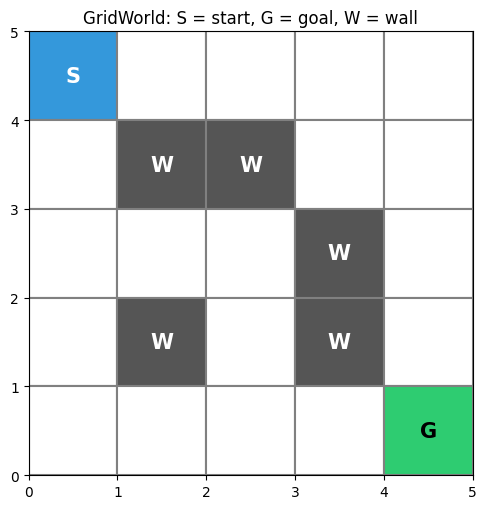

observation dim: 25 | actions: ['up', 'down', 'left', 'right']


In [3]:
# ============================================================
# GridWorld（離散行動）
# ============================================================

GRID_N = 5
GRID_WALLS = {(1, 1), (1, 2), (3, 1), (2, 3), (3, 3)}
GRID_GOAL = (4, 4)
GRID_MOVES = [(-1, 0), (1, 0), (0, -1), (0, 1)]   # up, down, left, right
MOVE_NAMES = ["up", "down", "left", "right"]


class GridWorld:
    '''方針勾配の練習用の最小 MDP。142 の GridWorld と同じ考え方。'''

    def __init__(self, max_steps: int = 60):
        self.max_steps = max_steps

    def reset(self):
        self.pos = (0, 0)
        self.t = 0
        return self.observe()

    def observe(self):
        v = np.zeros(GRID_N * GRID_N, dtype=np.float32)
        v[self.pos[0] * GRID_N + self.pos[1]] = 1.0
        return v

    def step(self, action: int):
        dr, dc = GRID_MOVES[action]
        r, c = self.pos[0] + dr, self.pos[1] + dc
        if 0 <= r < GRID_N and 0 <= c < GRID_N and (r, c) not in GRID_WALLS:
            self.pos = (r, c)          # 壁と外周にぶつかったら動かない
        self.t += 1
        at_goal = self.pos == GRID_GOAL
        reward = 1.0 if at_goal else -0.02
        done = at_goal or self.t >= self.max_steps
        return self.observe(), reward, done, {"at_goal": at_goal}


# --- 図2: 環境の可視化 ---
fig, ax = plt.subplots(figsize=(5.2, 5.2))
for r in range(GRID_N):
    for c in range(GRID_N):
        if (r, c) in GRID_WALLS:
            face, label = "#555555", "W"
        elif (r, c) == GRID_GOAL:
            face, label = "#2ECC71", "G"
        elif (r, c) == (0, 0):
            face, label = "#3498DB", "S"
        else:
            face, label = "#FFFFFF", ""
        ax.add_patch(Rectangle((c, GRID_N - 1 - r), 1, 1,
                               facecolor=face, edgecolor="gray", lw=1.5))
        if label:
            ax.text(c + 0.5, GRID_N - 1 - r + 0.5, label, ha="center", va="center",
                    fontsize=15, fontweight="bold",
                    color="white" if label in ("W", "S") else "black")
ax.set_xlim(0, GRID_N); ax.set_ylim(0, GRID_N)
ax.set_xticks(range(GRID_N + 1)); ax.set_yticks(range(GRID_N + 1))
ax.set_aspect("equal"); ax.grid(False)
ax.set_title("GridWorld: S = start, G = goal, W = wall")
plt.tight_layout(); plt.show()

env = GridWorld()
env.reset()
print("observation dim:", env.observe().shape[0], "| actions:", MOVE_NAMES)

---

<a id="reinforce"></a>
## 4. REINFORCE — 方針勾配定理

### 目的関数

方針のパラメータ $\theta$ を、期待収益を最大化するように動かしたい：

$$J(\theta) = \mathbb{E}_{\tau \sim \pi_\theta}\left[ \sum_{t=0}^{T} \gamma^t r_t \right]$$

問題は、$\tau$（軌跡）の分布自体が $\theta$ に依存することです。素朴に微分できません。

### 対数微分トリック

$\nabla_\theta p_\theta(\tau) = p_\theta(\tau)\, \nabla_\theta \log p_\theta(\tau)$ を使うと、

$$\nabla_\theta J(\theta) = \mathbb{E}_{\tau}\left[ \sum_{t} \nabla_\theta \log \pi_\theta(a_t \mid s_t)\, G_t \right]$$

が得られます（$G_t = \sum_{k \ge t} \gamma^{k-t} r_k$ はその時刻以降の収益）。

**意味**: 良い結果（$G_t$ が大きい）につながった行動の対数確率を上げ、
悪い結果につながった行動の対数確率を下げる。たったこれだけです。

### 実装上の形

勾配を直接書くのではなく、**損失**を

$$L(\theta) = -\frac{1}{N}\sum \log \pi_\theta(a_t \mid s_t)\, G_t$$

と定義して自動微分に任せます（$G_t$ は定数として扱う＝`detach` する）。
符号が反転しているのは、最大化を最小化に直すためです。

In [4]:
# ============================================================
# 方針ネットワークと軌跡収集
# ============================================================

def mlp(n_in: int, n_out: int, hidden: int = 64) -> nn.Sequential:
    return nn.Sequential(
        nn.Linear(n_in, hidden), nn.Tanh(),
        nn.Linear(hidden, n_out),
    )


def discounted_returns(rewards, gamma: float) -> np.ndarray:
    '''G_t = r_t + gamma * G_{t+1} を後ろから計算する。'''
    out = np.zeros(len(rewards), dtype=np.float32)
    acc = 0.0
    for i in range(len(rewards) - 1, -1, -1):
        acc = rewards[i] + gamma * acc
        out[i] = acc
    return out


def collect_grid_batch(policy, n_episodes: int, gamma: float):
    '''方針で n_episodes 本のエピソードを回し、(状態, 行動, 収益, 収益の合計) を返す。'''
    states, actions, returns, ep_returns, reached = [], [], [], [], []
    for _ in range(n_episodes):
        env = GridWorld()
        s = env.reset()
        ep_s, ep_a, ep_r = [], [], []
        for _ in range(env.max_steps):
            with torch.no_grad():
                logits = policy(torch.as_tensor(s))
            a = int(torch.distributions.Categorical(logits=logits).sample())
            s2, r, done, info = env.step(a)
            ep_s.append(s); ep_a.append(a); ep_r.append(r)
            s = s2
            if done:
                break
        states += ep_s
        actions += ep_a
        returns += list(discounted_returns(ep_r, gamma))
        ep_returns.append(float(np.sum(ep_r)))
        reached.append(bool(info["at_goal"]))
    return (torch.as_tensor(np.array(states)),
            torch.as_tensor(np.array(actions)),
            torch.as_tensor(np.array(returns, dtype=np.float32)),
            float(np.mean(ep_returns)),
            float(np.mean(reached)))


print("helpers ready")

helpers ready


### 3つの推定量を同じコードで比べる

次のセルで、**勾配の中の重み**だけを変えた3手法を回します。
方針ネットワークも学習率も収集するエピソード数もすべて同じにして、
重みの違いだけが結果の違いになるようにします。

| 手法 | $\log \pi$ にかける重み | 狙い |
|---|---|---|
| REINFORCE | $G_t$ | 素朴な方針勾配 |
| + ベースライン | $G_t - b$（$b$ はバッチ平均） | 平均を引いて分散を下げる |
| A2C | $G_t - V_\phi(s_t)$ | **状態ごとの**基準値を学習して引く |

ベースライン $b$ は行動に依存しなければ**勾配の期待値を変えません**（不偏なまま分散だけ下がる）。
これが「引いてよい」ことの根拠です。A2C はその $b$ を状態の関数 $V_\phi(s)$ にした版です。

In [5]:
# ============================================================
# REINFORCE / +ベースライン / A2C を同条件で学習
# ============================================================

def train_grid(method: str, updates: int = 200, batch_episodes: int = 16,
               gamma: float = 0.98, lr_pi: float = 5e-3, lr_v: float = 1e-2,
               seed: int = SEED):
    '''method in {"reinforce", "baseline", "a2c"}。学習曲線と勾配ノルムを返す。'''
    torch.manual_seed(seed)
    np.random.seed(seed)

    policy = mlp(GRID_N * GRID_N, 4)
    opt_pi = torch.optim.Adam(policy.parameters(), lr=lr_pi)
    value = mlp(GRID_N * GRID_N, 1)
    opt_v = torch.optim.Adam(value.parameters(), lr=lr_v)

    curve, success, grad_norms = [], [], []
    for _ in range(updates):
        S, A, G, mean_return, reach_rate = collect_grid_batch(policy, batch_episodes, gamma)

        if method == "reinforce":
            weight = G
        elif method == "baseline":
            weight = G - G.mean()                 # 行動に依存しない定数
        elif method == "a2c":
            weight = (G - value(S).squeeze(-1)).detach()
            loss_v = ((value(S).squeeze(-1) - G) ** 2).mean()
            opt_v.zero_grad(); loss_v.backward(); opt_v.step()
        else:
            raise ValueError(method)

        log_prob = torch.log_softmax(policy(S), dim=-1).gather(1, A[:, None]).squeeze(1)
        loss_pi = -(log_prob * weight).mean()
        opt_pi.zero_grad()
        loss_pi.backward()
        gn = torch.sqrt(sum((p.grad ** 2).sum() for p in policy.parameters()))
        grad_norms.append(float(gn))
        opt_pi.step()

        curve.append(mean_return)
        success.append(reach_rate)

    return {"curve": np.array(curve), "success": np.array(success),
            "grad_norms": np.array(grad_norms)}


t0 = time.time()
results = {m: train_grid(m) for m in ["reinforce", "baseline", "a2c"]}
print(f"trained 3 methods in {time.time() - t0:.1f}s")
for m, r in results.items():
    print(f"  {m:10s} return {r['curve'][:20].mean():+.3f} -> {r['curve'][-20:].mean():+.3f}"
          f"   goal rate {r['success'][-20:].mean():.2f}"
          f"   grad-norm mean {r['grad_norms'].mean():.4f}")

trained 3 methods in 4.9s
  reinforce  return -0.044 -> +0.854   goal rate 1.00   grad-norm mean 0.0913
  baseline   return +0.008 -> +0.859   goal rate 1.00   grad-norm mean 0.0156
  a2c        return +0.031 -> +0.859   goal rate 1.00   grad-norm mean 0.0101


---

<a id="baseline"></a>
## 5. ベースラインと Advantage — 分散を実測する

学習曲線だけ見ると3手法は似た場所に到達します。**違いは勾配の分散に出ます**。
そこを数字で見るのがこの節の目的です。

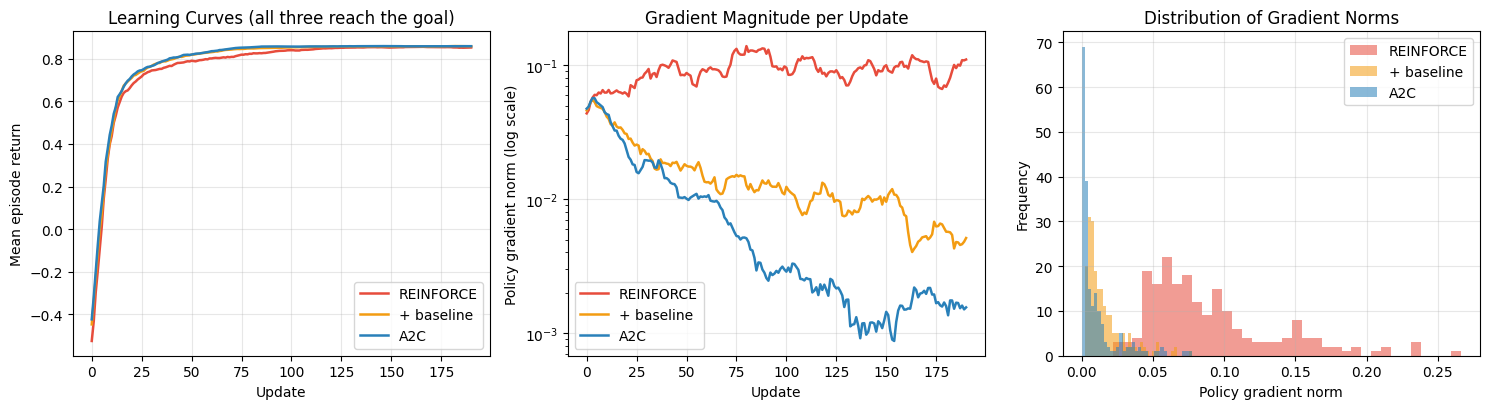

gradient norm statistics
method            mean       std       max
REINFORCE       0.0913    0.0459    0.2663   (1.00x of REINFORCE)
+ baseline      0.0156    0.0136    0.0778   (0.17x of REINFORCE)
A2C             0.0101    0.0147    0.0774   (0.11x of REINFORCE)


In [6]:
# ============================================================
# 図3: 学習曲線と勾配ノルムの比較（分散低減の実測）
# ============================================================

COLORS_M = {"reinforce": "#E74C3C", "baseline": "#F39C12", "a2c": "#2980B9"}
LABELS_M = {"reinforce": "REINFORCE", "baseline": "+ baseline", "a2c": "A2C"}


def smooth(x, k=10):
    if len(x) < k:
        return x
    return np.convolve(x, np.ones(k) / k, mode="valid")


fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

ax = axes[0]
for m, r in results.items():
    ax.plot(smooth(r["curve"]), color=COLORS_M[m], lw=1.8, label=LABELS_M[m])
ax.set_xlabel("Update")
ax.set_ylabel("Mean episode return")
ax.set_title("Learning Curves (all three reach the goal)")
ax.legend()

ax = axes[1]
for m, r in results.items():
    ax.semilogy(smooth(r["grad_norms"]), color=COLORS_M[m], lw=1.8, label=LABELS_M[m])
ax.set_xlabel("Update")
ax.set_ylabel("Policy gradient norm (log scale)")
ax.set_title("Gradient Magnitude per Update")
ax.legend()

ax = axes[2]
for m, r in results.items():
    ax.hist(r["grad_norms"], bins=35, alpha=0.55, color=COLORS_M[m], label=LABELS_M[m])
ax.set_xlabel("Policy gradient norm")
ax.set_ylabel("Frequency")
ax.set_title("Distribution of Gradient Norms")
ax.legend()

plt.tight_layout()
plt.show()

print("gradient norm statistics")
print(f"{'method':12s} {'mean':>9s} {'std':>9s} {'max':>9s}")
base = results["reinforce"]["grad_norms"].mean()
for m, r in results.items():
    g = r["grad_norms"]
    print(f"{LABELS_M[m]:12s} {g.mean():9.4f} {g.std():9.4f} {g.max():9.4f}"
          f"   ({g.mean() / base:.2f}x of REINFORCE)")

### 読み取れること

- **ベースラインを引くだけで勾配ノルムが一桁近く下がる**。収益 $G_t$ はこの環境では
  だいたい正の値（ゴールで +1）なので、ベースラインなしだと「どの行動も確率を上げよう」と
  いう方向に押され、違いは大きさの差だけになります。平均を引くと
  「平均より良かった行動だけを上げる」に変わります。
- **A2C はさらに下がる**。$V_\phi(s_t)$ は状態ごとの基準値なので、
  「ゴール付近だから収益が高いだけ」なのか「その行動が良かった」のかを切り分けられます。
- 学習曲線は似ていても、分散が小さいほど**学習率を上げられる・崩れにくい**という
  実務上の差になります。これは Notebook 110-116（最適化）の「勾配の分散」と同じ話です。

> **ベースラインは何でもよいのか**: 行動 $a_t$ に依存しなければ何でも不偏です。
> 状態に依存してよい（＝$V(s)$ でよい）、というのが Actor-Critic の出発点です。
> 逆に**行動に依存する量を引くとバイアスが入る**ので、$Q(s,a)$ をそのまま引いてはいけません。

---

<a id="armworld"></a>
## 6. ArmWorld — 連続行動・画像観測・言語指示の実験基盤

ここから Unit 15 の共通環境 **ArmWorld** を使います。170-174 の全章がこれを使い回します。

```
notebooks/vla/utils/armworld.py
```

| 項目 | 内容 |
|---|---|
| 本体 | 2リンク平面アーム（肩・肘の2関節）＋ 色付きブロック3個 |
| 観測 | ① 画像 64x64 RGB（NumPy で直接ラスタライズ）② 固有感覚 7次元 |
| 行動 | 連続2次元 **[-1, 1] 正規化** ＋ グリッパ1次元 |
| 指示 | テンプレート生成の自然文（`"touch the red block"` 等） |
| 報酬 | 目標との距離の減少量（＝進捗）。到達でボーナス |
| 依存 | **PyTorch と NumPy だけ**。gymnasium / MuJoCo を使わない |

**なぜ自作するのか**: 既存150本は外部シミュレータ依存ゼロで CPU 完結し、
`seed` で再現します。ArmWorld も同じ方針を守ります（移行方法は第10節）。

**この環境が一度に埋める穴**: 連続行動 / 画像観測 / 固有感覚 / 言語指示 / 順運動学 SE(2)。
これらは VLA に必須で、既存150本のどこにもありませんでした。

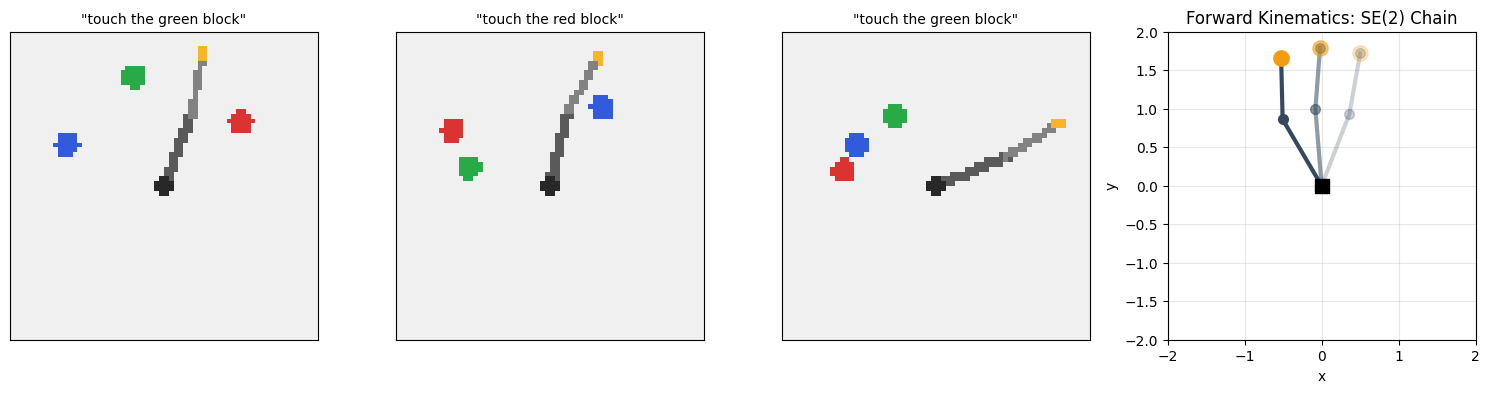

image      : (64, 64, 3) uint8
proprio    : [0.361 0.933 0.981 0.192 0.5   1.72  0.   ]
instruction: touch the green block
state_vec  : (9,) = proprio(7) + target-relative(2)


In [7]:
# ============================================================
# 図4: ArmWorld の観測・指示・順運動学
# ============================================================

fig, axes = plt.subplots(1, 4, figsize=(15, 4.0))

for i, ax in enumerate(axes[:3]):
    env = ArmWorld(task="reach", seed=100 + i)
    obs = env.reset(seed=100 + i)
    ax.imshow(obs["image"])
    ax.set_title(f'"{obs["instruction"]}"', fontsize=10)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)

# 右端: 順運動学（Notebook 53 の剛体変換の2次元版）
ax = axes[3]
env = ArmWorld(task="reach", seed=100)
env.reset(seed=100)
for frac, alpha in [(0.0, 0.25), (0.5, 0.55), (1.0, 1.0)]:
    theta = env.theta + frac * np.array([0.9, -0.7])
    elbow, eef = forward_kinematics(theta)
    ax.plot([0, elbow[0], eef[0]], [0, elbow[1], eef[1]], "-o",
            color="#34495E", alpha=alpha, lw=3, ms=7)
    ax.plot(eef[0], eef[1], "o", color="#F39C12", alpha=alpha, ms=11)
ax.plot(0, 0, "ks", ms=10)
ax.set_xlim(-2, 2); ax.set_ylim(-2, 2); ax.set_aspect("equal")
ax.set_xlabel("x"); ax.set_ylabel("y")
ax.set_title("Forward Kinematics: SE(2) Chain")

plt.tight_layout()
plt.show()

obs = ArmWorld(task="reach", seed=100).reset(seed=100)
print("image      :", obs["image"].shape, obs["image"].dtype)
print("proprio    :", np.round(obs["proprio"], 3))
print("instruction:", obs["instruction"])
print("state_vec  :", ArmWorld(task='reach', seed=100).state_vec().shape,
      "= proprio(7) + target-relative(2)")

### 行動空間の設計が学習しやすさを決める

ArmWorld は行動空間を2通り選べます。**同じタスクでも、どちらを選ぶかで難しさが変わります**。

| `action_space` | 行動の意味 | 必要な写像 |
|---|---|---|
| `"joint"` | 関節角の増分 $\Delta\theta$ | 方針が**ヤコビアンの逆**を学ぶ必要がある |
| `"eef"` （既定） | エンドエフェクタを動かす方向 $\Delta x$ | 環境側が減衰付き最小二乗で $\Delta\theta$ に変換する |

`"eef"`（作業空間制御 / operational space control）では、状態に入っている
「目標までの相対ベクトル」をほぼそのまま出力すればよいので、学習が速くなります。
実機のロボットでも、どちらの空間で指令を出すかは実際の設計判断です。
Notebook 174 でこの2つを定量比較します。

### もうひとつの設計: 行動の正規化

`ArmWorld` は行動を **$[-1,1]$ に正規化**して受け取り、内部でスケールします。
これは見た目の些細な違いではありません。方針の標準偏差が 0.3 程度のとき、
行動の実スケール（0.2 rad）で直接出力させると**サンプルの大半が範囲外にクリップされ、
勾配が嘘になります**。正規化しておけば分布が飽和しません。

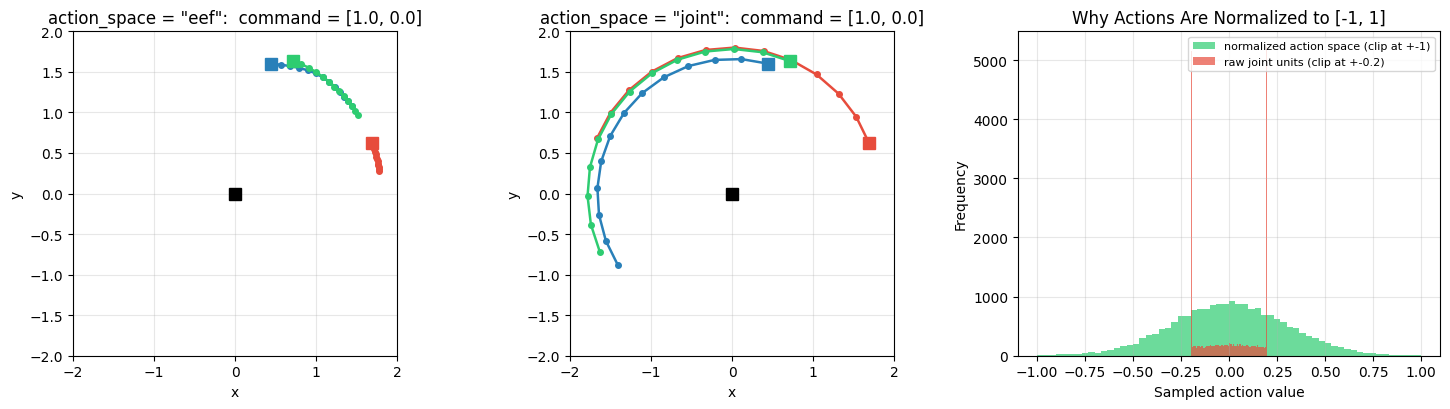

policy std = 0.3: fraction of samples that would be clipped
  raw joint units (+-0.2): 50.4%  <- the gradient is mostly a lie
  normalized      (+-1.0): 0.1%


In [8]:
# ============================================================
# 図5: 行動空間の違い — 同じ「右に動かしたい」指令の結果
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

command = np.array([1.0, 0.0])      # 「+x 方向へ」という同一の指令

for ax, space in zip(axes[:2], ["eef", "joint"]):
    ax.set_title(f'action_space = "{space}":  command = [1.0, 0.0]')
    for seed, color in [(7, "#2980B9"), (11, "#E74C3C"), (23, "#2ECC71")]:
        env = ArmWorld(task="reach", seed=seed, image_obs=False, action_space=space)
        env.reset(seed=seed)
        path = []
        for _ in range(12):
            _, eef = forward_kinematics(env.theta)
            path.append(eef.copy())
            env.step(np.concatenate([command, [0.0]]))
        _, eef = forward_kinematics(env.theta)
        path.append(eef.copy())
        path = np.array(path)
        ax.plot(path[:, 0], path[:, 1], "o-", color=color, ms=4, lw=1.8)
        ax.plot(path[0, 0], path[0, 1], "s", color=color, ms=9)
    ax.plot(0, 0, "ks", ms=9)
    ax.set_xlim(-2, 2); ax.set_ylim(-2, 2); ax.set_aspect("equal")
    ax.set_xlabel("x"); ax.set_ylabel("y")

# 右: 正規化しないと分布が飽和する
ax = axes[2]
samples = np.random.normal(0.0, 0.3, size=20000)
ax.hist(np.clip(samples, -1, 1), bins=60, alpha=0.7, color="#2ECC71",
        label="normalized action space (clip at +-1)")
ax.hist(np.clip(samples, -MAX_DELTA, MAX_DELTA), bins=60, alpha=0.7, color="#E74C3C",
        label=f"raw joint units (clip at +-{MAX_DELTA})")
ax.set_xlabel("Sampled action value")
ax.set_ylabel("Frequency")
ax.set_title("Why Actions Are Normalized to [-1, 1]")
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

clipped = np.mean(np.abs(samples) > MAX_DELTA)
print(f"policy std = 0.3: fraction of samples that would be clipped")
print(f"  raw joint units (+-{MAX_DELTA}): {clipped:.1%}  <- the gradient is mostly a lie")
print(f"  normalized      (+-1.0): {np.mean(np.abs(samples) > 1.0):.1%}")

---

<a id="gaussian"></a>
## 7. ガウス方針による連続制御

連続行動の方針は、ネットワークに**分布のパラメータ**を出させます。

$$\pi_\theta(a \mid s) = \mathcal{N}\big(\mu_\theta(s),\ \sigma_\theta^2\big)$$

- $\mu_\theta(s)$: 状態ごとの平均（ネットワークの出力）
- $\sigma_\theta$: 標準偏差。ここでは**状態に依存しない学習パラメータ**にします
  （$\log \sigma$ を持つ：正値制約を自然に満たすため）

行動を選ぶのはサンプリング $a \sim \pi_\theta(\cdot\mid s)$、
学習に使うのは $\log \pi_\theta(a\mid s)$ です。離散のときの
`log_softmax(...).gather(...)` が `Normal(mu, std).log_prob(a).sum()` に置き換わるだけで、
**方針勾配の骨格は何も変わりません**。

### 報酬の設計: 進捗報酬

ArmWorld の報酬は「目標との距離の**減少量**」です。

$$r_t = d_{t-1} - d_t \quad (+\ 0.5 \text{ if reached})$$

距離そのものの符号反転 $-d_t$ でも学習はできますが、進捗の形にすると収益が
$\sum_t (d_{t-1} - d_t) = d_0 - d_T$ と**畳み込まれて**スケールが小さく安定します。
これは Notebook 142 で見た「報酬の設計が学習の難しさを決める」の続きです。

In [9]:
# ============================================================
# ガウス方針と連続版 A2C
# ============================================================

class GaussianPolicy(nn.Module):
    '''連続行動の方針。平均は状態の関数、log 標準偏差は共有パラメータ。'''

    def __init__(self, obs_dim: int = 9, act_dim: int = 2, log_std_init: float = -0.7):
        super().__init__()
        self.mu = mlp(obs_dim, act_dim)
        # 出力層を小さく初期化しておくと、初期方針が暴れない
        self.mu[-1].weight.data *= 0.1
        nn.init.zeros_(self.mu[-1].bias)
        self.log_std = nn.Parameter(torch.full((act_dim,), float(log_std_init)))

    def distribution(self, obs: torch.Tensor) -> torch.distributions.Normal:
        return torch.distributions.Normal(self.mu(obs), self.log_std.exp())


def collect_arm_batch(policy, seeds, task: str = "reach", max_steps: int = 50):
    '''ArmWorld のエピソードをまとめて回す。報酬は進捗（距離の減少量）。'''
    batch_states, batch_actions, batch_returns = [], [], []
    successes, episode_returns = [], []
    for sd in seeds:
        env = ArmWorld(task=task, seed=int(sd), image_obs=False, max_steps=max_steps)
        env.reset(seed=int(sd))
        _, eef = forward_kinematics(env.theta)
        prev_dist = float(np.linalg.norm(eef - env.target))
        ep_s, ep_a, ep_r = [], [], []
        for _ in range(max_steps):
            state = env.state_vec()
            with torch.no_grad():
                action = policy.distribution(torch.as_tensor(state)).sample().numpy()
            _, _, done, info = env.step(np.concatenate([action, [0.0]]))
            ep_s.append(state); ep_a.append(action)
            ep_r.append(prev_dist - info["distance"])     # 進捗報酬
            prev_dist = info["distance"]
            if done:
                break
        if info["success"]:
            ep_r[-1] += 0.5                               # 到達ボーナス
        batch_states.append(np.array(ep_s, dtype=np.float32))
        batch_actions.append(np.array(ep_a, dtype=np.float32))
        batch_returns.append(discounted_returns(ep_r, gamma=0.98))
        successes.append(bool(info["success"]))
        episode_returns.append(float(np.sum(ep_r)))
    return (torch.as_tensor(np.concatenate(batch_states)),
            torch.as_tensor(np.concatenate(batch_actions)),
            torch.as_tensor(np.concatenate(batch_returns)),
            float(np.mean(episode_returns)), float(np.mean(successes)))


def train_arm_a2c(updates: int = 250, batch_episodes: int = 8, lr_pi: float = 1e-3,
                  lr_v: float = 3e-3, entropy_coef: float = 1e-3, seed: int = SEED,
                  shared_trunk: bool = False):
    '''連続行動の A2C。shared_trunk=True で「方針と価値でトランクを共有」する版になる。'''
    torch.manual_seed(seed)
    np.random.seed(seed)

    policy = GaussianPolicy()
    if shared_trunk:
        # 共有版: 方針の隠れ層をそのまま価値ヘッドの入力にする
        trunk = policy.mu[:-1]
        value_head = nn.Linear(64, 1)
        params_v = list(value_head.parameters())

        def value_of(x):
            return value_head(trunk(x)).squeeze(-1)
    else:
        value_net = mlp(9, 1)
        params_v = list(value_net.parameters())

        def value_of(x):
            return value_net(x).squeeze(-1)

    opt_pi = torch.optim.Adam(policy.parameters(), lr=lr_pi)
    opt_v = torch.optim.Adam(params_v, lr=lr_v)

    curve, success = [], []
    episode = 0
    for _ in range(updates):
        S, A, G, mean_ret, succ = collect_arm_batch(
            policy, range(episode, episode + batch_episodes))
        episode += batch_episodes

        advantage = (G - value_of(S)).detach()
        advantage = (advantage - advantage.mean()) / (advantage.std() + 1e-6)

        dist = policy.distribution(S)
        log_prob = dist.log_prob(A).sum(-1)
        loss_pi = -(log_prob * advantage).mean() - entropy_coef * dist.entropy().sum(-1).mean()
        opt_pi.zero_grad(); loss_pi.backward()
        nn.utils.clip_grad_norm_(policy.parameters(), 0.5)
        opt_pi.step()

        loss_v = ((value_of(S) - G) ** 2).mean()
        opt_v.zero_grad(); loss_v.backward()
        nn.utils.clip_grad_norm_(params_v, 0.5)
        opt_v.step()

        curve.append(mean_ret); success.append(succ)

    return policy, np.array(curve), np.array(success)


t0 = time.time()
arm_policy, arm_curve, arm_success = train_arm_a2c()
print(f"continuous A2C: {len(arm_curve)} updates x 8 episodes in {time.time() - t0:.1f}s")
print(f"  success rate: {arm_success[:25].mean():.2f} (start) -> {arm_success[-25:].mean():.2f} (end)")

continuous A2C: 250 updates x 8 episodes in 4.4s
  success rate: 0.16 (start) -> 0.98 (end)


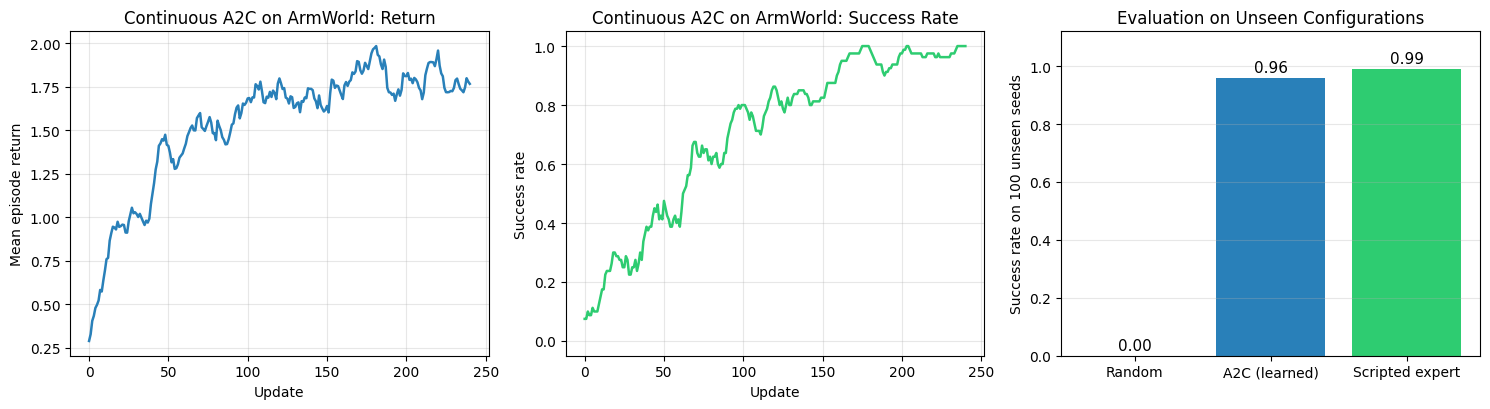

random policy   : 0.00
A2C (learned)   : 0.96
scripted expert : 0.99  <- 171 ではこれを教師データにする


In [10]:
# ============================================================
# 図6: 連続 A2C の学習曲線と、学習した方針の評価
# ============================================================

def greedy_action(policy):
    '''評価用: 分布の平均をそのまま使う（決定論的方針）。'''
    def act(state):
        with torch.no_grad():
            mu = policy.mu(torch.as_tensor(state)).numpy()
        return np.concatenate([mu, [0.0]])
    return act


# 未知のシードで評価（学習に使った seed 0-1999 とは重ならない）
eval_seeds = range(5000, 5100)
policy_act = greedy_action(arm_policy)
expert = ScriptedExpert()
policy_success, expert_success, random_success = [], [], []
for sd in eval_seeds:
    policy_success.append(rollout(ArmWorld(task="reach", seed=sd, image_obs=False), policy_act)["success"])
    expert_success.append(rollout(ArmWorld(task="reach", seed=sd, image_obs=False), expert)["success"])
    random_success.append(rollout(ArmWorld(task="reach", seed=sd, image_obs=False),
                                  lambda s: np.append(np.random.uniform(-1, 1, 2), 0.0))["success"])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

ax = axes[0]
ax.plot(smooth(arm_curve, 10), color="#2980B9", lw=1.8)
ax.set_xlabel("Update")
ax.set_ylabel("Mean episode return")
ax.set_title("Continuous A2C on ArmWorld: Return")

ax = axes[1]
ax.plot(smooth(arm_success, 10), color="#2ECC71", lw=1.8)
ax.set_xlabel("Update")
ax.set_ylabel("Success rate")
ax.set_ylim(-0.05, 1.05)
ax.set_title("Continuous A2C on ArmWorld: Success Rate")

ax = axes[2]
names = ["Random", "A2C (learned)", "Scripted expert"]
vals = [np.mean(random_success), np.mean(policy_success), np.mean(expert_success)]
bars = ax.bar(names, vals, color=["#95A5A6", "#2980B9", "#2ECC71"])
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.02, f"{v:.2f}", ha="center", fontsize=11)
ax.set_ylim(0, 1.12)
ax.set_ylabel("Success rate on 100 unseen seeds")
ax.set_title("Evaluation on Unseen Configurations")
ax.grid(axis="x")

plt.tight_layout()
plt.show()

print(f"random policy   : {np.mean(random_success):.2f}")
print(f"A2C (learned)   : {np.mean(policy_success):.2f}")
print(f"scripted expert : {np.mean(expert_success):.2f}  <- 171 ではこれを教師データにする")

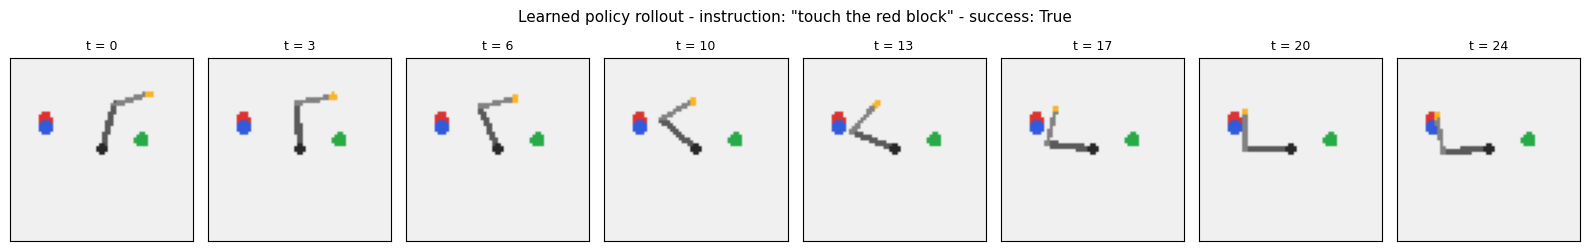

episode length: 24 steps, final distance 0.129


In [11]:
# ============================================================
# 図7: 学習した方針のロールアウト（画像で見る）
# ============================================================

env = ArmWorld(task="reach", seed=5007)
obs = env.reset(seed=5007)
frames = [obs["image"]]
for _ in range(env.max_steps):
    obs, _, done, info = env.step(policy_act(env.state_vec()))
    frames.append(obs["image"])
    if done:
        break

n_show = min(8, len(frames))
idx = np.linspace(0, len(frames) - 1, n_show).astype(int)
fig, axes = plt.subplots(1, n_show, figsize=(2.0 * n_show, 2.6))
for ax, i in zip(axes, idx):
    ax.imshow(frames[i])
    ax.set_title(f"t = {i}", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.suptitle(f'Learned policy rollout - instruction: "{obs["instruction"]}"'
             f' - success: {info["success"]}', fontsize=11)
plt.tight_layout()
plt.show()

print(f"episode length: {len(frames) - 1} steps, final distance {info['distance']:.3f}")

---

<a id="pitfall"></a>
## 8. 設計上の分かれ道: 方針と価値でトランクを共有するか

実装の教科書では「actor と critic で特徴抽出層を共有する」とよく書かれます。
計算が節約でき、表現も共有できる——はずです。

一方で、共有には次の経路があります。

- 価値ヘッドは最初ランダムなので、$V_\phi(s)$ と $G_t$ の誤差が大きい
- その大きな勾配が**共有トランクを通って方針側にも流れる**
- 方針が乱れる → 収集される軌跡が悪くなる → さらに価値が学べない

この経路が実際にどれだけ効くのかは、**測らないと分かりません**。測ってみます。

shared-trunk run: 4.4s


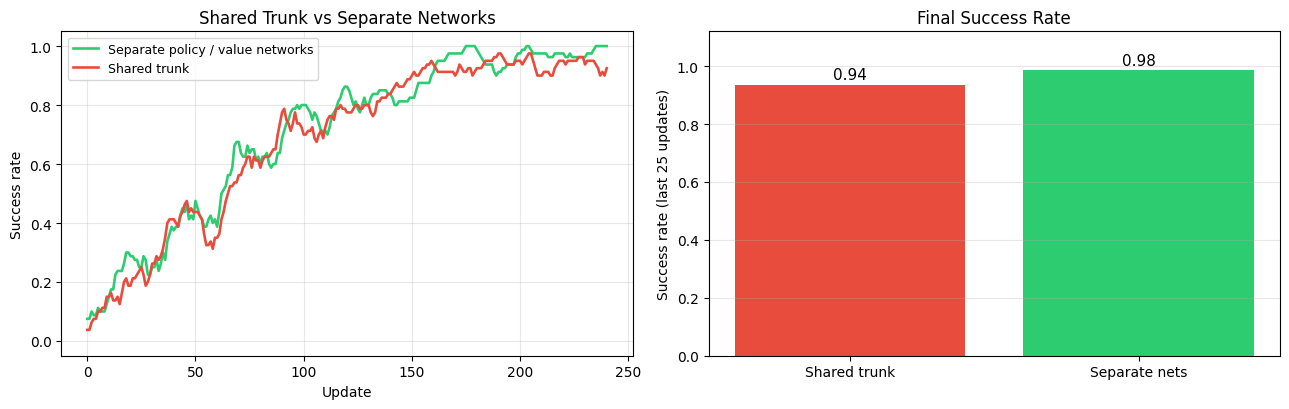

shared trunk  : 0.94
separate nets : 0.98
difference    : +0.05

この設定では『壊れる』のではなく『一貫して少し劣る』という結果になった。
効きの大きさは価値損失のスケール（報酬スケール・価値の学習率）に依存する。
報酬を10倍にすると価値誤差も10倍になり、同じ経路がもっと強く効く。

共有が常に悪いわけでもない（画像入力で特徴抽出が重いときは共有が有利になりうる）。
要点は『価値損失の勾配が方針に流れる経路があるかを意識する』こと。
共有するなら価値損失に小さな係数をかけるか、トランクへの勾配を止める。


In [12]:
# ============================================================
# 図8: トランク共有 vs 分離（実測）
# ============================================================

t0 = time.time()
_, shared_curve, shared_success = train_arm_a2c(shared_trunk=True)
print(f"shared-trunk run: {time.time() - t0:.1f}s")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

ax = axes[0]
ax.plot(smooth(arm_success, 10), color="#2ECC71", lw=1.9, label="Separate policy / value networks")
ax.plot(smooth(shared_success, 10), color="#E74C3C", lw=1.9, label="Shared trunk")
ax.set_xlabel("Update"); ax.set_ylabel("Success rate")
ax.set_ylim(-0.05, 1.05)
ax.set_title("Shared Trunk vs Separate Networks")
ax.legend(fontsize=9)

ax = axes[1]
names = ["Shared trunk", "Separate nets"]
vals = [shared_success[-25:].mean(), arm_success[-25:].mean()]
bars = ax.bar(names, vals, color=["#E74C3C", "#2ECC71"])
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.02, f"{v:.2f}", ha="center", fontsize=11)
ax.set_ylim(0, 1.12)
ax.set_ylabel("Success rate (last 25 updates)")
ax.set_title("Final Success Rate")
ax.grid(axis="x")

plt.tight_layout()
plt.show()

gap = arm_success[-25:].mean() - shared_success[-25:].mean()
print(f"shared trunk  : {shared_success[-25:].mean():.2f}")
print(f"separate nets : {arm_success[-25:].mean():.2f}")
print(f"difference    : {gap:+.2f}")
print()
print("この設定では『壊れる』のではなく『一貫して少し劣る』という結果になった。")
print("効きの大きさは価値損失のスケール（報酬スケール・価値の学習率）に依存する。")
print("報酬を10倍にすると価値誤差も10倍になり、同じ経路がもっと強く効く。")
print()
print("共有が常に悪いわけでもない（画像入力で特徴抽出が重いときは共有が有利になりうる）。")
print("要点は『価値損失の勾配が方針に流れる経路があるかを意識する』こと。")
print("共有するなら価値損失に小さな係数をかけるか、トランクへの勾配を止める。")

---

<a id="links"></a>
## 9. 既出知識との接続

### Notebook 167（RLHF）で図解された PPO が、ここで初めて実装になる

167 では RLHF の流れを「SFT → 報酬モデル → **PPO で方針最適化**」と図解しましたが、
方針最適化そのものは実装していませんでした。いま実装した
「$\log \pi$ に Advantage をかけて上げ下げする」が、まさにその中身です。

PPO は本章の A2C に**信頼領域**を足したものです。

$$L^{\text{PPO}} = \mathbb{E}\left[\min\left(\rho_t A_t,\ \text{clip}(\rho_t, 1-\epsilon, 1+\epsilon) A_t\right)\right],
\quad \rho_t = \frac{\pi_\theta(a_t\mid s_t)}{\pi_{\theta_{\text{old}}}(a_t\mid s_t)}$$

比 $\rho_t$ をクリップして「1回の更新で方針が遠くへ飛ばない」ようにする、という差分です。
RLHF で KL 制約が付いていたのと同じ動機です。

### Notebook 143（DreamerV3）の actor-critic に戻れる

143 では RSSM が作った**想像の軌跡**の上で actor と critic を学習していました。
本章との違いは「軌跡をどこから取るか」だけです。

| | 本章 (A2C) | DreamerV3 (143) |
|---|---|---|
| 軌跡の出どころ | 実環境のロールアウト | **世界モデル内の想像** |
| Advantage | $G_t - V_\phi(s_t)$ | 同じ（λ-return を使う） |
| 利点 | 実データなので正しい | 実環境の試行が要らない |
| 弱点 | 試行回数が必要 | モデル誤差が方針に乗る |

143 のコードを読み返すと、`actor_critic` 部分が本章と同じ構造をしていることが分かります。
Notebook 174 では、この「想像で評価する」を VLA の行動選択に組み込みます。

---

<a id="gym"></a>
## 10. 補足: gymnasium / MuJoCo への移行

ArmWorld は意図的に外部依存を持ちませんが、API は Gym 互換に寄せてあります。
実環境に移すときは次のように読み替えます。

```python
# ArmWorld
env = ArmWorld(task="reach", seed=0)
obs = env.reset(seed=0)                 # dict: image / proprio / target / instruction
obs, reward, done, info = env.step(action)

# gymnasium（5タプル・truncated が分離している）
import gymnasium as gym
env = gym.make("Reacher-v5")            # MuJoCo の2リンクアーム
obs, info = env.reset(seed=0)
obs, reward, terminated, truncated, info = env.step(action)
done = terminated or truncated
```

移行時に実際に効いてくる差分：

| 論点 | ArmWorld | gymnasium / MuJoCo |
|---|---|---|
| 終了の区別 | `done` のみ | `terminated`（目的達成）と `truncated`（時間切れ）を分ける |
| 価値のブートストラップ | 進捗報酬なので影響が小さい | `truncated` では $V(s_T)$ を足さないと**バイアスが入る** |
| 行動のスケール | $[-1,1]$ 正規化を環境が担当 | `env.action_space.low/high` を自分で見る |
| 物理 | 運動学だけ（質量・摩擦なし） | 完全な力学。制御周期とソルバ設定が効く |
| 観測 | 画像を自分でラスタライズ | `render_mode="rgb_array"` とカメラ設定 |

**`truncated` の扱いは最初に踏む罠**です。時間切れのエピソード末端を「価値0の終端」として
扱うと、エージェントは「時間切れ＝悪いこと」と誤学習します。

---

<a id="summary"></a>
## 11. まとめとチートシート

### この章で学んだこと

- **連続行動では $\arg\max_a Q(s,a)$ が解けない**。離散化は次元の呪いに当たる。
  だから方針そのものをパラメータ化する。
- **方針勾配**は「良い結果につながった行動の対数確率を上げる」だけ。
  実装は $-\log\pi(a|s) \cdot (\text{重み})$ を損失にして自動微分に任せる。
- **ベースラインを引いても不偏**（行動に依存しなければ）。勾配ノルムが実測で一桁近く下がった。
- **A2C** はベースラインを状態の関数 $V_\phi(s)$ にしたもの。さらに分散が下がる。
- **行動空間の設計**（作業空間 vs 関節空間、$[-1,1]$ 正規化）が学習しやすさを大きく変える。
- **方針と価値でトランクを共有すると、この設定では一貫して少し劣った**
  （第8節の実測を参照）。初期の価値誤差が共有層を通って方針に流れる経路があるため。

### チートシート

```python
# 離散（カテゴリカル方針）
logits  = policy(states)                                   # (B, n_actions)
log_pi  = torch.log_softmax(logits, -1).gather(1, actions[:, None]).squeeze(1)

# 連続（ガウス方針）
dist    = torch.distributions.Normal(mu_net(states), log_std.exp())
actions = dist.sample()                                    # 行動を決めるのはこれだけ
log_pi  = dist.log_prob(actions).sum(-1)                   # 次元方向に足す

# 共通の損失（重みは detach する）
advantage = (returns - value_net(states)).detach()
advantage = (advantage - advantage.mean()) / (advantage.std() + 1e-6)
loss = -(log_pi * advantage).mean() - entropy_coef * dist.entropy().sum(-1).mean()
```

### よくある間違い

| 間違い | 何が起きるか | 対処 |
|---|---|---|
| 重み（収益・Advantage）を `detach` しない | 収益経由で勾配が流れて意味が壊れる | `.detach()` を付ける |
| 行動を正規化せずに出力させる | サンプルの大半がクリップされ**勾配が嘘になる** | 行動空間を $[-1,1]$ にする |
| Advantage を正規化しない | 報酬スケールがそのまま学習率に化ける | バッチ単位で標準化する |
| 方針と価値でトランクを共有する | 初期の価値誤差が方針に流れて性能が落ちる | 分離する／価値損失に小さな係数／`detach` |
| 時間切れを価値0の終端として扱う | 「時間切れは悪い」と誤学習する | `truncated` では $V(s_T)$ をブートストラップ |
| 行動に依存する量をベースラインに使う | 勾配にバイアスが入る | $V(s)$ など状態のみの関数にする |

### 次のノートブックへ

本章の A2C は未知配置でスクリプト方針に近い成功率まで届きました（第7節の実測）。
しかし、そこに至るまでに **2,000 エピソードの試行錯誤**を要しています。

一方 `ScriptedExpert` は**試行を1回もせずに**同じ水準を出します。
実機のロボットで2,000回の失敗を許容できる現場はほとんどありません
（部品が壊れる・時間が足りない・危険）。

「正解の動きを見せられるなら、試行錯誤する必要があるのか？」——
これが Notebook 171（模倣学習と行動トークン化）の出発点です。
次章では、本章の `ScriptedExpert` が作った軌跡を**教師データ**として使います。

---

<a id="quiz"></a>
## 12. 自己評価クイズ

### Q1: なぜ連続行動で Q学習が使えないのか

**問題**: 連続行動空間で $\arg\max_a Q(s,a)$ が解けない理由と、
離散化という対策の限界を説明してください。

<details>
<summary>答えを見る</summary>

行動が非可算無限なので「全部試して最大を選ぶ」ができません。$Q$ が $a$ について
凸でも線形でもない一般のニューラルネットなので、最大化そのものが毎ステップの
非凸最適化問題になります。

離散化すると候補数が $k^d$（$k$ 分割・$d$ 次元）になり、7関節・11分割で約2000万通りです。
さらに分割を粗くすると滑らかな指令が出せず（本章の図1右）、細かくすると候補が爆発します。
</details>

---

### Q2: ベースラインを引いてよい理由

**問題**: $\nabla_\theta J = \mathbb{E}[\nabla_\theta \log \pi_\theta(a|s)(G_t - b)]$ で、
$b$ が行動 $a$ に依存しなければ勾配の期待値が変わらないのはなぜですか。
また $b = Q(s,a)$ としてはいけないのはなぜですか。

<details>
<summary>答えを見る</summary>

$\mathbb{E}_a[\nabla_\theta \log \pi_\theta(a|s)] = \sum_a \pi_\theta(a|s)
\frac{\nabla_\theta \pi_\theta(a|s)}{\pi_\theta(a|s)} = \nabla_\theta \sum_a \pi_\theta(a|s)
= \nabla_\theta 1 = 0$ なので、行動に依存しない $b$ を掛けた項の期待値は 0 になります。
期待値は変わらず、分散だけが変わります。

$b=Q(s,a)$ は行動に依存するので上の導出が成立せず、バイアスが入ります
（$b$ と $\nabla\log\pi$ が相関してしまう）。状態のみの関数 $V(s)$ なら安全です。
</details>

---

### Q3: 行動の正規化

**問題**: 方針の標準偏差が 0.3、行動の実スケールが $\pm 0.2$ のとき、
行動を正規化せずに出力させると何が起きますか。

<details>
<summary>答えを見る</summary>

サンプルの約 50%（本章の実測）が範囲外になり、環境側でクリップされます。
クリップされた行動は**どれだけ外側に出ても同じ結果**になるのに、
`log_prob` はクリップ前の値で計算されるため、勾配が「実際には効かない方向」を
押すことになります。学習が進まない、あるいは発散します。

対策は行動空間を $[-1,1]$ に正規化して環境側でスケールすること（ArmWorld の方式）か、
tanh で squash して対数確率に変換のヤコビアン補正を入れることです。
</details>

---

### Q4: トランク共有が壊れる機構

**問題**: 方針と価値で特徴抽出層を共有すると学習が壊れることがあります。
その機構を説明し、それでも共有したい場合の対処を挙げてください。

<details>
<summary>答えを見る</summary>

価値ヘッドは初期化直後ランダムなので $V_\phi(s)$ と $G_t$ の二乗誤差が大きく、
その勾配が共有層を通って方針側のパラメータも動かします。方針が壊れると
収集される軌跡が悪化し、価値も学べなくなる悪循環になります（本章の図8で実測）。

対処: ①ネットワークを分離する ②価値損失に小さな係数をかける
③価値損失の勾配を共有層で止める（`detach`）④価値ヘッドの出力を小さく初期化する。
画像入力など特徴抽出が重い場合は共有の利得が大きいため、②③を併用するのが実務的です。
</details>

---

### Q5: A2C と DreamerV3 の関係

**問題**: 本章の A2C と Notebook 143 の DreamerV3 の actor-critic は、
どこが同じでどこが違いますか。違いから生じる長所と短所を述べてください。

<details>
<summary>答えを見る</summary>

**同じ**: 方針を $\log\pi \times$ Advantage で更新し、critic が状態価値を回帰する構造。

**違い**: 軌跡の出どころ。本章は実環境のロールアウト、DreamerV3 は RSSM が生成した
**想像の軌跡**です。

- Dreamer の長所: 実環境での試行が要らない（サンプル効率が極端に良い）。
  想像なら並列に大量のロールアウトを作れる。
- Dreamer の短所: 世界モデルの誤差がそのまま方針に乗る。モデルが知らない状態領域で
  自信を持って間違える。だから想像ホライゾンを短く保つ（142 の「想像回数の収穫逓減」と同じ理由）。
</details>

In [13]:
# ============================================================
# 最終サマリ
# ============================================================

print("=" * 70)
print("Notebook 170 完了: 方針勾配と Actor-Critic")
print("=" * 70)
print(f'''
【離散 GridWorld（同条件で3手法）】

  REINFORCE    : 勾配ノルム平均 {results['reinforce']['grad_norms'].mean():.4f}
  + ベースライン: 勾配ノルム平均 {results['baseline']['grad_norms'].mean():.4f}
                 ({results['baseline']['grad_norms'].mean() / results['reinforce']['grad_norms'].mean():.2f}x)
  A2C          : 勾配ノルム平均 {results['a2c']['grad_norms'].mean():.4f}
                 ({results['a2c']['grad_norms'].mean() / results['reinforce']['grad_norms'].mean():.2f}x)

  -> 到達する性能は同じでも、分散が一桁近く違う。

【連続 ArmWorld（ガウス方針 + A2C）】

  ランダム方針     : 成功率 {np.mean(random_success):.2f}
  A2C で学習       : 成功率 {np.mean(policy_success):.2f}   (未知の100配置)
  スクリプト方針   : 成功率 {np.mean(expert_success):.2f}

  トランク共有     : 成功率 {shared_success[-25:].mean():.2f}
  ネットワーク分離 : 成功率 {arm_success[-25:].mean():.2f}

【次章への問い】

  A2C がこの成功率に達するまでに使った試行: 250 更新 x 8 = 2,000 エピソード
  スクリプト方針が使った試行:               0 エピソード

  実機で2,000回の失敗は許容できない。デモを見せられるなら、学ばせ方は変わるはず。
  -> Notebook 171: 模倣学習と行動トークン化
''')
print("=" * 70)

Notebook 170 完了: 方針勾配と Actor-Critic

【離散 GridWorld（同条件で3手法）】

  REINFORCE    : 勾配ノルム平均 0.0913
  + ベースライン: 勾配ノルム平均 0.0156
                 (0.17x)
  A2C          : 勾配ノルム平均 0.0101
                 (0.11x)

  -> 到達する性能は同じでも、分散が一桁近く違う。

【連続 ArmWorld（ガウス方針 + A2C）】

  ランダム方針     : 成功率 0.00
  A2C で学習       : 成功率 0.96   (未知の100配置)
  スクリプト方針   : 成功率 0.99

  トランク共有     : 成功率 0.94
  ネットワーク分離 : 成功率 0.98

【次章への問い】

  A2C がこの成功率に達するまでに使った試行: 250 更新 x 8 = 2,000 エピソード
  スクリプト方針が使った試行:               0 エピソード

  実機で2,000回の失敗は許容できない。デモを見せられるなら、学ばせ方は変わるはず。
  -> Notebook 171: 模倣学習と行動トークン化

